# Exoploratory Data Analysis

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set_style('whitegrid')

# import warnings
# warnings.filterwarnings('ignore')

## Loading Data

In [3]:
df=pd.read_csv('data/PRSA_data.csv')
df

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
43819,43820,2014,12,31,19,8.0,-23,-2.0,1034.0,NW,231.97,0,0
43820,43821,2014,12,31,20,10.0,-22,-3.0,1034.0,NW,237.78,0,0
43821,43822,2014,12,31,21,10.0,-22,-3.0,1034.0,NW,242.70,0,0
43822,43823,2014,12,31,22,8.0,-22,-4.0,1034.0,NW,246.72,0,0


 adding date column using existing columns

In [4]:
df['date']=pd.to_datetime(df[['year','month','day','hour']])
# print(df.drop(['year','month','day','hour'],axis=1))
df=df.drop(['year','month','day','hour'],axis=1)
df = df.sort_values('date').reset_index(drop=True)
df

,No,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir,date
0,1,NaN,-21,-11.0,1021.0,NW,1.79,0,0,2010-01-01 00:00:00
1,2,NaN,-21,-12.0,1020.0,NW,4.92,0,0,2010-01-01 01:00:00
2,3,NaN,-21,-11.0,1019.0,NW,6.71,0,0,2010-01-01 02:00:00
3,4,NaN,-21,-14.0,1019.0,NW,9.84,0,0,2010-01-01 03:00:00
4,5,NaN,-20,-12.0,1018.0,NW,12.97,0,0,2010-01-01 04:00:00
...,...,...,...,...,...,...,...,...,...,...
43819,43820,8.0,-23,-2.0,1034.0,NW,231.97,0,0,2014-12-31 19:00:00
43820,43821,10.0,-22,-3.0,1034.0,NW,237.78,0,0,2014-12-31 20:00:00
43821,43822,10.0,-22,-3.0,1034.0,NW,242.70,0,0,2014-12-31 21:00:00
43822,43823,8.0,-22,-4.0,1034.0,NW,246.72,0,0,2014-12-31 22:00:00


### Data Overview

In [5]:
print('Shape:', df.shape)
print('\nColumn dtypes:')
print(df.dtypes)
print('\nDate range:', df['date'].min(), '→', df['date'].max())
print('Duplicate timestamps:', df['date'].duplicated().sum())
print('\nWind direction (cbwd) categories:')
print(df['cbwd'].value_counts())

Shape: (43824, 10)

Column dtypes:
No                int64
pm2.5           float64
DEWP              int64
TEMP            float64
PRES            float64
cbwd             object
Iws             float64
Is                int64
Ir                int64
date     datetime64[ns]
dtype: object

Date range: 2010-01-01 00:00:00 → 2014-12-31 23:00:00
Duplicate timestamps: 0

Wind direction (cbwd) categories:
cbwd
SE    15290
NW    14150
cv     9387
NE     4997
Name: count, dtype: int64


In [6]:
df.describe().round(2)

,No,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir,date
count,43824.00,41757.00,43824.00,43824.00,43824.00,43824.00,43824.00,43824.00,43824
mean,21912.50,98.61,1.82,12.45,1016.45,23.89,0.05,0.19,2012-07-01 23:30:00
min,1.00,0.00,-40.00,-19.00,991.00,0.45,0.00,0.00,2010-01-01 00:00:00
25%,10956.75,29.00,-10.00,2.00,1008.00,1.79,0.00,0.00,2011-04-02 11:45:00
50%,21912.50,72.00,2.00,14.00,1016.00,5.37,0.00,0.00,2012-07-01 23:30:00
75%,32868.25,137.00,15.00,23.00,1025.00,21.91,0.00,0.00,2013-10-01 11:15:00
max,43824.00,994.00,28.00,42.00,1046.00,585.60,27.00,36.00,2014-12-31 23:00:00
std,12651.04,92.05,14.43,12.20,10.27,50.01,0.76,1.42,NaN


### Missing Values

       missing   pct
pm2.5     2067  4.72


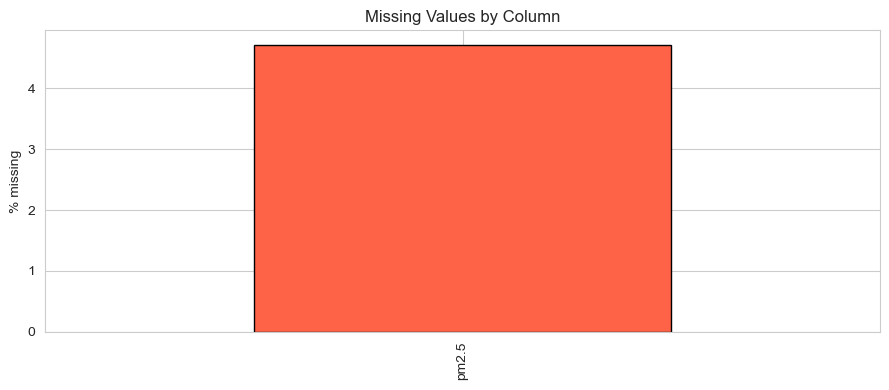

In [7]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
miss_tbl = pd.DataFrame({'missing': missing, 'pct': missing_pct})
print(miss_tbl[miss_tbl['missing'] > 0])

plt.figure(figsize=(9, 4))
miss_tbl[miss_tbl['missing'] > 0]['pct'].plot(kind='bar', color='tomato', edgecolor='black')
plt.ylabel('% missing')
plt.title('Missing Values by Column')
plt.tight_layout()
plt.show()

 We can notice that only the pm2.5 column has missing values

In [8]:
miss_tbl

,missing,pct
No,0,0.00
pm2.5,2067,4.72
DEWP,0,0.00
TEMP,0,0.00
PRES,0,0.00
cbwd,0,0.00
Iws,0,0.00
Is,0,0.00
Ir,0,0.00
date,0,0.00


* as missing values in pm2.5 are not usesful we should drop those rows

### Target Variable distribution

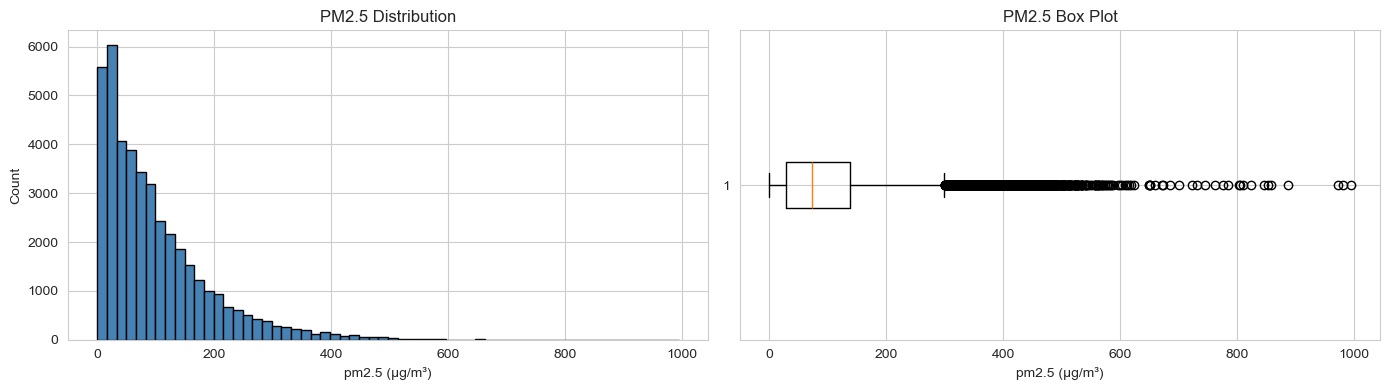

count    41757.00
mean        98.61
std         92.05
min          0.00
25%         29.00
50%         72.00
75%        137.00
max        994.00
Name: pm2.5, dtype: float64
Skew: 1.8


In [9]:
pm = df['pm2.5'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(pm, bins=60, color='steelblue', edgecolor='black')
axes[0].set_xlabel('pm2.5 (µg/m³)')
axes[0].set_ylabel('Count')
axes[0].set_title('PM2.5 Distribution')
axes[1].boxplot(pm, vert=False)
axes[1].set_xlabel('pm2.5 (µg/m³)')
axes[1].set_title('PM2.5 Box Plot')
plt.tight_layout()
plt.show()

print(pm.describe().round(2))
print('Skew:', round(pm.skew(), 2))

we can see from the plots that pm2.5 is left skewed with most values ranging between 0-200

### Time Series Analysis

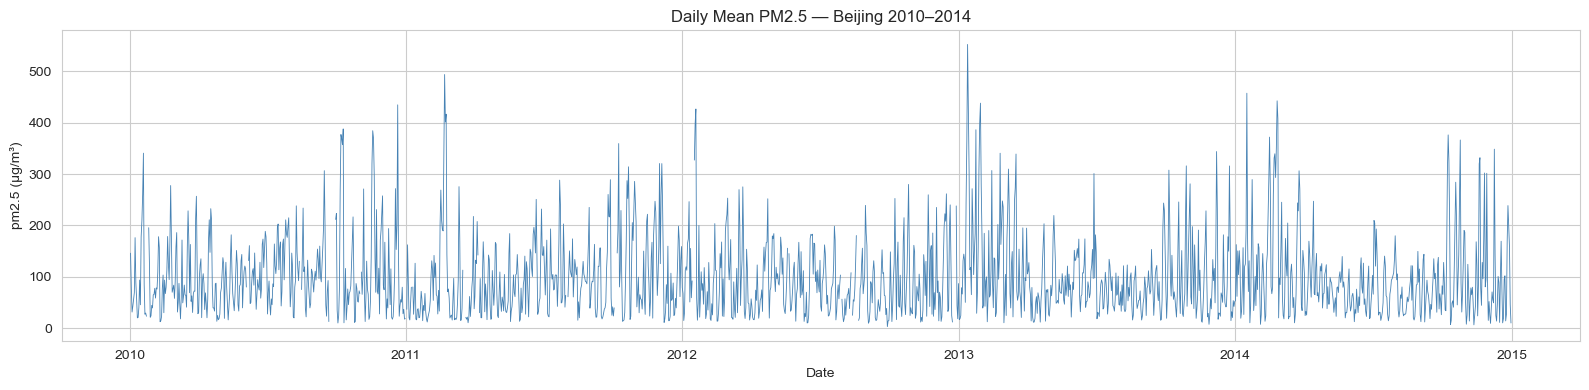

In [10]:
daily = df.set_index('date')['pm2.5'].resample('D').mean()
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(daily.index, daily.values, linewidth=0.6, color='steelblue')
ax.set_title('Daily Mean PM2.5 — Beijing 2010–2014')
ax.set_xlabel('Date'); ax.set_ylabel('pm2.5 (µg/m³)')
plt.tight_layout(); plt.show()

**we can see that the aqi spikes at start of the year** mostly due to the winter season

### Seasonality Analysis

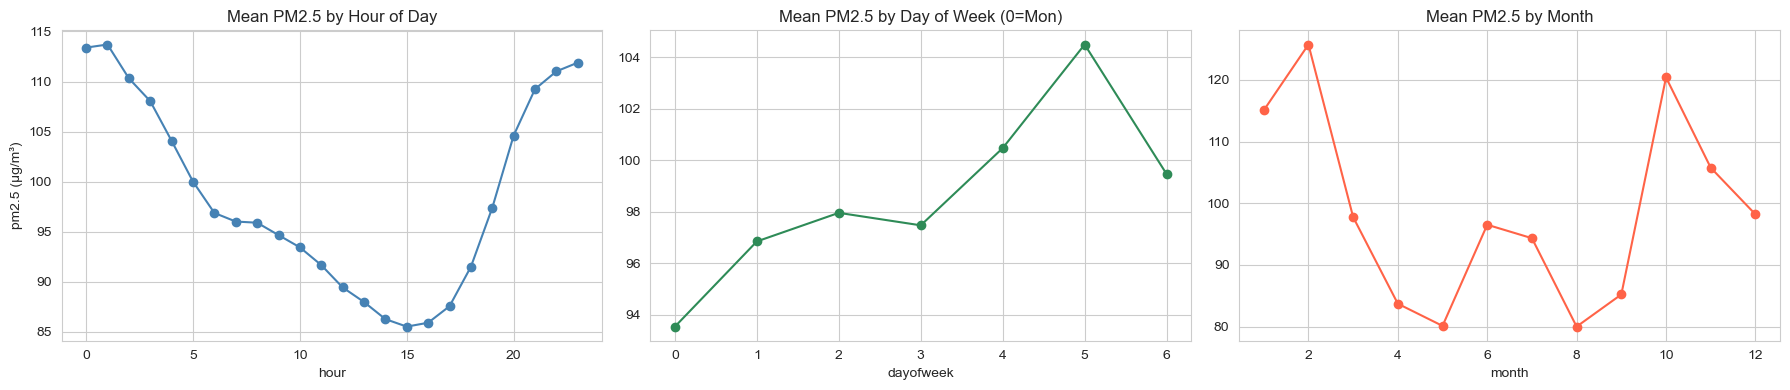

In [11]:
df['hour']      = df['date'].dt.hour
df['dayofweek'] = df['date'].dt.dayofweek
df['month']     = df['date'].dt.month

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
df.groupby('hour')['pm2.5'].mean().plot(ax=axes[0], marker='o', color='steelblue')
axes[0].set_title('Mean PM2.5 by Hour of Day'); axes[0].set_ylabel('pm2.5 (µg/m³)')
df.groupby('dayofweek')['pm2.5'].mean().plot(ax=axes[1], marker='o', color='seagreen')
axes[1].set_title('Mean PM2.5 by Day of Week (0=Mon)')
df.groupby('month')['pm2.5'].mean().plot(ax=axes[2], marker='o', color='tomato')
axes[2].set_title('Mean PM2.5 by Month')
plt.tight_layout()
plt.show()

From the Plots we can observe that particles are :
-  high during nights compared to day and least during noon
-  high in months of jan-feb and oct-dec which are winter months compared to the months of summer

so our initial observation of winter is correlated

### Correlation Analysis

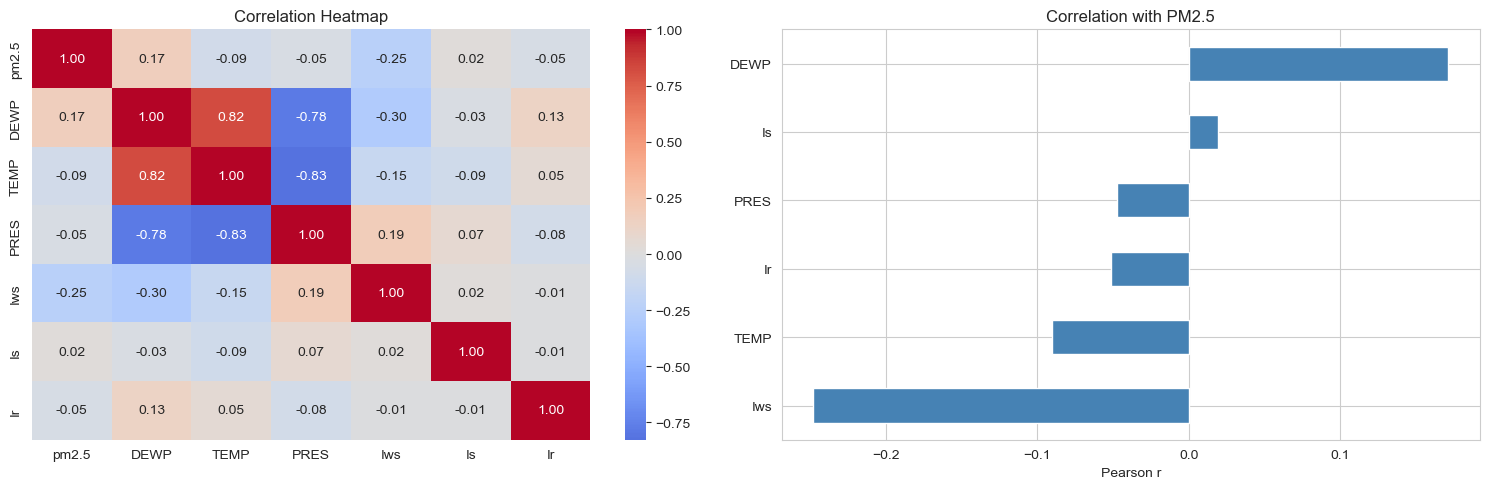

In [12]:
num_cols = ['pm2.5', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir']
corr = df[num_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('Correlation Heatmap')
corr['pm2.5'].drop('pm2.5').sort_values().plot(kind='barh', color='steelblue', ax=axes[1])
axes[1].set_title('Correlation with PM2.5'); axes[1].set_xlabel('Pearson r')
plt.tight_layout(); plt.show()

We can observe that DEWP(dew point) is highly correlated to the pm2.5 i.e. humidity
also Iws(cumulative wind speed) is inversely correlated to pm2.5 i.e wind disperses pollution

### Wind direction vs PM2.5

cbwd - categorical wind direction(NW, NE, SE, cv calm/variable) 

       mean  count
cbwd              
NE     90.2   4756
NW     70.1  13484
SE    110.8  14573
cv    126.2   8944


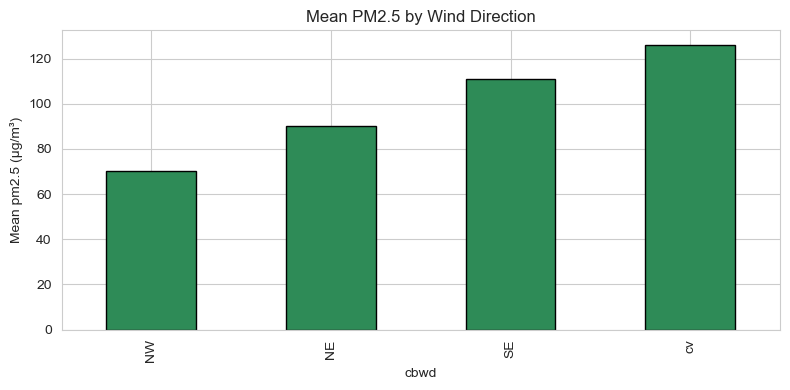

In [13]:
wind_means = df.groupby('cbwd')['pm2.5'].agg(['mean', 'count']).round(1)
print(wind_means)

plt.figure(figsize=(8, 4))
df.groupby('cbwd')['pm2.5'].mean().sort_values().plot(kind='bar', color='seagreen', edgecolor='black')
plt.ylabel('Mean pm2.5 (µg/m³)'); plt.title('Mean PM2.5 by Wind Direction')
plt.tight_layout(); plt.show()

for this region pollution is most when wind is calm and most pollution is carried by south west winds

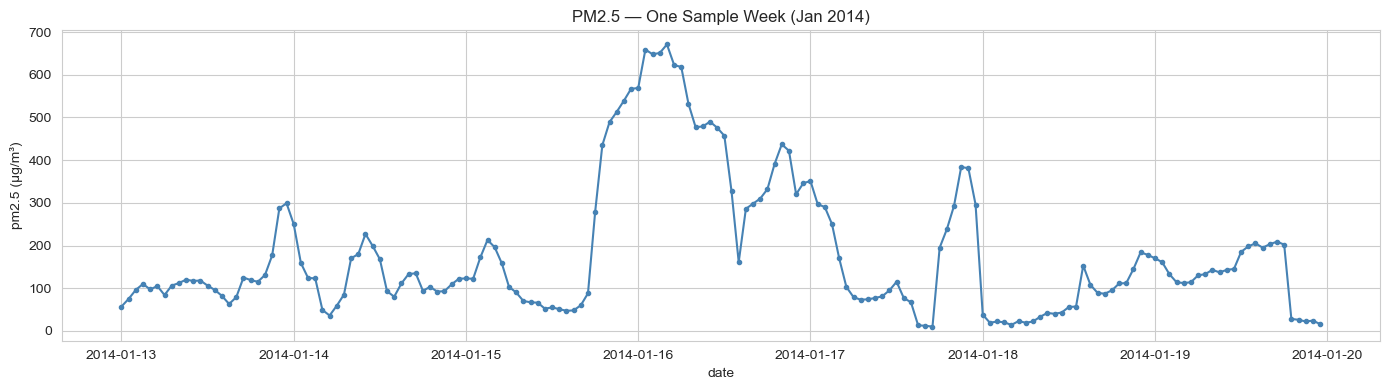

In [14]:
sample_week = df[(df['date'] >= '2014-01-13') & (df['date'] < '2014-01-20')]
plt.figure(figsize=(14, 4))
plt.plot(sample_week['date'], sample_week['pm2.5'], marker='.', color='steelblue')
plt.title('PM2.5 — One Sample Week (Jan 2014)')
plt.xlabel('date'); plt.ylabel('pm2.5 (µg/m³)')
plt.tight_layout(); plt.show()

# Summary

In [15]:
summary = pd.DataFrame({
    'Finding': [
        'Dataset size',
        'Date range',
        'Missing pm2.5 rows',
        'Target mean (µg/m³)',
        'Target median (µg/m³)',
        'Target max (µg/m³)',
        'Strongest weather corr (+)',
        'Strongest weather corr (−)',
        'Worst month',
        'Cleanest wind direction',
    ],
    'Value': [
        f'{len(df):,} hourly rows',
        f"{df['date'].min().date()} → {df['date'].max().date()}",
        f"{df['pm2.5'].isna().sum():,} ({df['pm2.5'].isna().mean()*100:.1f}%)",
        f"{df['pm2.5'].mean():.1f}",
        f"{df['pm2.5'].median():.1f}",
        f"{df['pm2.5'].max():.0f}",
        f"DEWP (r={df[['pm2.5','DEWP']].corr().iloc[0,1]:.2f})",
        f"Iws  (r={df[['pm2.5','Iws']].corr().iloc[0,1]:.2f})",
        f"month {df.groupby('month')['pm2.5'].mean().idxmax()}",
        f"{df.groupby('cbwd')['pm2.5'].mean().idxmin()}",
    ],
})
summary

,Finding,Value
0,Dataset size,"43,824 hourly rows"
1,Date range,2010-01-01 → 2014-12-31
2,Missing pm2.5 rows,"2,067 (4.7%)"
3,Target mean (µg/m³),98.6
4,Target median (µg/m³),72.0
5,Target max (µg/m³),994
6,Strongest weather corr (+),DEWP (r=0.17)
7,Strongest weather corr (−),Iws (r=-0.25)
8,Worst month,month 2
9,Cleanest wind direction,NW
